# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours

---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [7]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [8]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


### Phase 1 — Forensic Data Audit and Problem Formulation

**1. Dataset dimensions, class balance, missing values and duplicates**

The dataset contains 6,000 observations and 15 columns. It includes 4,389 benign files (73.15%) and 1,611 malware files (26.85%). There are 229 missing values in `Import_Count` and 289 in `Resource_Entropy`. No duplicate rows or duplicate identifiers were found. The dataset is moderately imbalanced, with benign files representing the majority class.

**2. Identifier and post-scan field**

`SHA256_File_ID` is a unique identifier and should be excluded because it does not provide meaningful predictive information. `VT_PostScan_Detections` must also be excluded because it contains antivirus detection information obtained after scanning. Using it would introduce target leakage and produce unrealistic evaluation results.

**3. Virtual_to_Raw_Size_Ratio**

The feature contains 59 suspicious values equal to `99999.0`. These values are likely caused by parser errors or invalid calculations. They should be replaced with missing values (NaN) and handled using median imputation to avoid introducing unrealistic numerical values into the model.

**4. Feature relationships**

Two important relationships to investigate are `Max_Section_Entropy` with `Suspicious_API_Imports`, and `Resource_Entropy` with `Is_Malware`. Malware files can exhibit different entropy levels and suspicious API-import patterns compared with benign files. A single linear boundary may not capture all these relationships, making nonlinear models such as Decision Trees and Random Forests useful candidates.

**5. Prediction task**

The objective is to classify Windows PE files as malicious or benign before execution. The positive class is malware (1), and the negative class is benign (0). A False Positive occurs when a legitimate file is classified as malware, while a False Negative occurs when a malicious file is classified as benign. False negatives represent a significant security risk because malicious files may pass through the detection system.

In [9]:
print("Shape:", df_pe.shape)
print("\nClass balance (counts):\n", df_pe["Is_Malware"].value_counts())
print("\nClass balance (%):\n", df_pe["Is_Malware"].value_counts(normalize=True).round(3))
print("\nMissing values:\n", df_pe.isna().sum())
print("\nDuplicate rows:", df_pe.duplicated().sum())
print("Duplicate file IDs:", df_pe["SHA256_File_ID"].duplicated().sum())

# Leakage check: how strongly does the post-scan field track the label?
print("\nMean VT_PostScan_Detections by class:")
print(df_pe.groupby("Is_Malware")["VT_PostScan_Detections"].describe())

display(df_pe.describe().T)

Shape: (6000, 15)

Class balance (counts):
 Is_Malware
0    4389
1    1611
Name: count, dtype: int64

Class balance (%):
 Is_Malware
0    0.732
1    0.268
Name: proportion, dtype: float64

Missing values:
 SHA256_File_ID                  0
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio       0
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
VT_PostScan_Detections          0
Is_Malware                      0
dtype: int64

Duplicate rows: 0
Duplicate file IDs: 0

Mean VT_PostScan_Detections by class:
             count       mean        std   min   25%   50%   75%   max
Is_Malware                                                            
0           4389.0   0.989747   0.821672   0.0   

,count,mean,std,min,25%,50%,75%,max
Max_Section_Entropy,6000.0,5.709010,1.170152,2.146111,4.821742,5.639862,6.604762,7.990000
Import_Count,5771.0,83.386866,50.301130,0.000000,41.184528,85.663796,120.408591,320.325585
Suspicious_API_Imports,6000.0,2.800167,3.094430,0.000000,1.000000,2.000000,3.000000,24.000000
Has_Valid_Signature,6000.0,0.630833,0.482619,0.000000,0.000000,1.000000,1.000000,1.000000
Has_RWX_Section,6000.0,0.149833,0.356938,0.000000,0.000000,0.000000,0.000000,1.000000
Virtual_to_Raw_Size_Ratio,6000.0,984.890348,9868.008483,0.367195,0.955570,1.129836,1.366755,99999.000000
Resource_Entropy,5711.0,4.535160,1.501097,0.000000,3.483114,4.432941,5.517712,7.990000
Num_Embedded_URLs_IPs,6000.0,1.468333,1.951742,0.000000,0.000000,1.000000,2.000000,11.000000
Abnormal_Compile_Timestamp,6000.0,0.114833,0.318847,0.000000,0.000000,0.000000,0.000000,1.000000
Num_Sections,6000.0,4.758667,1.784551,1.000000,3.000000,5.000000,6.000000,10.000000


Rows with Virtual_to_Raw_Size_Ratio == 99999.0: 59 (0.98%)

Ratio stats excluding 99999.0:
count    5941.000000
mean        1.582408
std         1.298046
min         0.367195
25%         0.953186
50%         1.126470
75%         1.355024
max         6.497630
Name: Virtual_to_Raw_Size_Ratio, dtype: float64


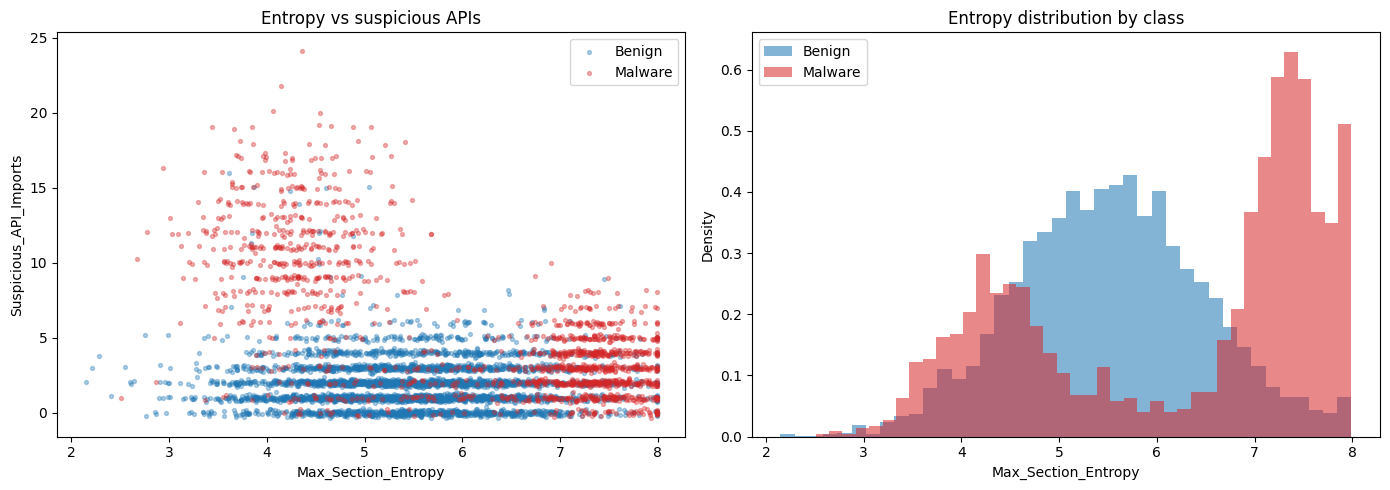

In [10]:
ratio = df_pe["Virtual_to_Raw_Size_Ratio"]
n_bad = (ratio == 99999.0).sum()
print(f"Rows with Virtual_to_Raw_Size_Ratio == 99999.0: {n_bad} ({n_bad/len(df_pe):.2%})")
print("\nRatio stats excluding 99999.0:")
print(ratio[ratio != 99999.0].describe())

rng_plot = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: entropy vs suspicious APIs (jitter on the discrete count axis)
for label, name, color in [(0, "Benign", "tab:blue"), (1, "Malware", "tab:red")]:
    sub = df_pe[df_pe["Is_Malware"] == label]
    jitter = rng_plot.normal(0, 0.12, len(sub))
    axes[0].scatter(sub["Max_Section_Entropy"], sub["Suspicious_API_Imports"] + jitter,
                    s=8, alpha=0.35, label=name, color=color)
axes[0].set_xlabel("Max_Section_Entropy")
axes[0].set_ylabel("Suspicious_API_Imports")
axes[0].set_title("Entropy vs suspicious APIs")
axes[0].legend()

# Plot 2: entropy distribution by class (shows non-linear / multi-modal pattern)
for label, name, color in [(0, "Benign", "tab:blue"), (1, "Malware", "tab:red")]:
    axes[1].hist(df_pe.loc[df_pe["Is_Malware"] == label, "Max_Section_Entropy"],
                 bins=40, alpha=0.55, label=name, color=color, density=True)
axes[1].set_xlabel("Max_Section_Entropy")
axes[1].set_ylabel("Density")
axes[1].set_title("Entropy distribution by class")
axes[1].legend()

plt.tight_layout()
plt.show()

In [11]:
TARGET = "Is_Malware"
y = df_pe[TARGET].astype(int)

X = df_pe.drop(columns=["SHA256_File_ID", "VT_PostScan_Detections", TARGET]).copy()
X["Virtual_to_Raw_Size_Ratio"] = X["Virtual_to_Raw_Size_Ratio"].replace(99999.0, np.nan)

print("X shape:", X.shape)
print("Remaining NaNs per column:\n", X.isna().sum())

X shape: (6000, 12)
Remaining NaNs per column:
 Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio      59
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
dtype: int64


### Phase 2 — Leakage-Free Preprocessing and Cross-Validation

**1. Development and test sets**

The dataset is divided using stratified sampling into 80% development data (4,800 observations) and 20% test data (1,200 observations). Stratification preserves the class distribution in both datasets. The test set remains untouched during model selection and threshold optimization.

**2. Preprocessing**

Median imputation is used to handle missing numerical values. RobustScaler is applied to Logistic Regression because scaling improves numerical optimization and reduces the influence of extreme values. Tree-based algorithms generally do not require feature scaling because they use decision thresholds rather than distance calculations. All preprocessing must be performed inside the pipeline to prevent data leakage between cross-validation folds.

**3. Candidate models**

The candidate algorithms are Logistic Regression as a linear baseline, Decision Tree as a single nonlinear model, Random Forest as a bagging ensemble, and LightGBM or HistGradientBoosting as a boosting model. Stacking can additionally combine different algorithms to improve predictive performance.

**4. Cross-validation evaluation**

Five-fold Stratified Cross-Validation is used to evaluate all candidate models. The evaluation metrics include training F1-score, validation F1-score, PR-AUC and average training time. These metrics allow comparison of predictive performance, generalization and computational cost.

**5. Bias and variance**

Logistic Regression may have higher bias because it assumes a linear decision boundary. A deep Decision Tree can have high variance because it may memorize training observations. Random Forest reduces variance by combining multiple decision trees. Boosting improves predictions by learning from previous errors. Stacking may improve performance by combining different algorithms, but its additional complexity and computational cost must be justified by measurable improvements.

### Decision Checkpoint 1

1. **Largest train-validation gap:** A deep Decision Tree is particularly susceptible to overfitting and may show a large difference between training and validation F1-scores.

2. **Logistic Regression competitiveness:** Logistic Regression provides an important baseline. If its validation F1-score and PR-AUC are close to more complex models, it may be preferable because of its simplicity and interpretability.

3. **Random Forest versus Decision Tree:** Random Forest generally reduces variance and improves generalization by combining multiple decision trees.

4. **Boosting performance:** Boosting should be preferred only if its PR-AUC improvement is meaningful enough to justify its additional computational and maintenance costs.

5. **Stacking justification:** Stacking is justified only if it provides a measurable improvement over individual models. If the improvement is small, its additional complexity and computational cost are not worthwhile.

In [12]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print("Dev:", X_dev.shape, "| Test (lockbox):", X_test.shape)
print("Dev prevalence:", round(y_dev.mean(), 3), "| Test prevalence:", round(y_test.mean(), 3))

def make_pipe(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", RobustScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

# Boosting: LightGBM if installed, otherwise sklearn's HistGradientBoosting (labelled accurately)
try:
    from lightgbm import LGBMClassifier
    boost = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                           random_state=SEED, verbose=-1, n_jobs=1)
    BOOST_NAME = "LightGBM"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    boost = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEED)
    BOOST_NAME = "HistGradientBoosting (sklearn)"
print("Boosting model used:", BOOST_NAME)

lr_model = LogisticRegression(max_iter=2000, random_state=SEED)
dt_model = DecisionTreeClassifier(max_depth=None, random_state=SEED)   # deliberately deep
rf_model = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1)

# Heterogeneous stacking (imputer outside, so base learners get clean data)
stack_model = StackingClassifier(
    estimators=[
        ("lr", Pipeline([("scaler", RobustScaler()),
                         ("m", LogisticRegression(max_iter=2000, random_state=SEED))])),
        ("rf", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)),
        ("boost", clone(boost)),
    ],
    final_estimator=LogisticRegression(max_iter=2000, random_state=SEED),
    stack_method="predict_proba",
    cv=5,
    n_jobs=1,
)

candidates = {
    "Logistic Regression": make_pipe(lr_model, scale=True),
    "Decision Tree (deep)": make_pipe(dt_model),
    "Random Forest": make_pipe(rf_model),
    BOOST_NAME: make_pipe(boost),
    "Stacking": make_pipe(stack_model),
}

Dev: (4800, 12) | Test (lockbox): (1200, 12)
Dev prevalence: 0.269 | Test prevalence: 0.268
Boosting model used: LightGBM


In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"f1": "f1", "ap": "average_precision"}

rows = []
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_dev, y_dev, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    rows.append({
        "Model": name,
        "Train F1": res["train_f1"].mean(),
        "Val F1": res["test_f1"].mean(),
        "Val F1 std": res["test_f1"].std(),
        "Val PR-AUC": res["test_ap"].mean(),
        "Fit time (s/fold)": res["fit_time"].mean(),
    })

cv_table = pd.DataFrame(rows).set_index("Model")
cv_table["Train-Val gap"] = cv_table["Train F1"] - cv_table["Val F1"]
display(cv_table.round(4).sort_values("Val PR-AUC", ascending=False))

,Train F1,Val F1,Val F1 std,Val PR-AUC,Fit time (s/fold),Train-Val gap
Model,,,,,,
Stacking,0.9572,0.9244,0.0088,0.9084,18.2387,0.0328
Logistic Regression,0.9231,0.9238,0.0084,0.9080,0.0413,-0.0007
Random Forest,1.0000,0.9237,0.0091,0.9054,4.4108,0.0763
LightGBM,0.9979,0.9217,0.0091,0.9033,0.4978,0.0762
Decision Tree (deep),1.0000,0.8301,0.0135,0.7330,0.0752,0.1699


### Decision checkpoint 1 — Select a shortlist

Answer with evidence from your table:
1. Which model shows the largest train–validation gap? What does it suggest?
2. Does the linear baseline already perform competitively?
3. Does Random Forest improve on the single tree?
4. Does boosting improve PR-AUC enough to justify its complexity?
5. Is stacking justified by the measured gain, runtime and deployment context? Do not assume that a more complex model must win.

**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements.

In [14]:
# Fit on dev only (reused later in the error-forensics and threshold cells)
fitted = {name: clone(pipe).fit(X_dev, y_dev) for name, pipe in candidates.items()}

batch = X_test.iloc[:1000]          # features only, no labels used
lat_rows = []
for name, model in fitted.items():
    model.predict_proba(batch)      # warm-up
    times = []
    for _ in range(10):
        t0 = time.perf_counter()
        model.predict_proba(batch)
        times.append((time.perf_counter() - t0) * 1000)
    lat_rows.append({"Model": name,
                     "ms / 1,000 files (median)": np.median(times),
                     "ms / 1,000 files (min)": np.min(times)})

display(pd.DataFrame(lat_rows).set_index("Model").round(2))
print("Note: single machine/runtime, batch inference, 10 repeats; not a production benchmark.")

,"ms / 1,000 files (median)","ms / 1,000 files (min)"
Model,,
Logistic Regression,7.15,5.10
Decision Tree (deep),4.90,2.51
Random Forest,90.28,81.24
LightGBM,38.43,36.26
Stacking,75.35,73.77


Note: single machine/runtime, batch inference, 10 repeats; not a production benchmark.


### Phase 3 — Error Forensics and TreeSHAP Explainability

**1. Generate prediction probabilities**

Logistic Regression and the selected tree ensemble are used to generate malware probabilities for the same held-out test observations. This allows direct comparison of their classification decisions.

**2. Identify a disagreement**

A disagreement occurs when Logistic Regression classifies an observation as benign while the tree model classifies it as malware. The selected observation should have a ground-truth malware label. If no observation satisfies these conditions, another meaningful disagreement should be selected and reported honestly.

**3. Analyze the selected observation**

The investigation should report the ground-truth label, feature values, Logistic Regression probability, tree model probability and both predictions. These values must come from the actual selected test observation.

**4. Global SHAP explanation**

The SHAP beeswarm plot identifies the features that have the greatest influence on the model's predictions. Features with larger absolute SHAP values contribute more strongly to the model output. It provides an overview of how different PE characteristics influence malware classification.

**5. Local SHAP explanation**

The SHAP waterfall plot explains an individual prediction by showing how each feature contributes to increasing or decreasing the model output. It helps analysts understand why a particular PE file received a suspicious classification.

SHAP explains model behavior but does not prove causality or establish that a file is malicious.

In [15]:
TREE_NAME = "Random Forest"
THR_DIAG = 0.50   # diagnostic only

p_lr = fitted["Logistic Regression"].predict_proba(X_test)[:, 1]
p_tree = fitted[TREE_NAME].predict_proba(X_test)[:, 1]
pred_lr = (p_lr >= THR_DIAG).astype(int)
pred_tree = (p_tree >= THR_DIAG).astype(int)
y_true = y_test.values

# Malware that LR calls benign but the tree model calls malware
mask = (y_true == 1) & (pred_lr == 0) & (pred_tree == 1)
print("Malware caught by tree but missed by LR:", mask.sum())

if mask.sum() > 0:
    idx = np.where(mask)[0]
    i = idx[np.argmax(p_tree[idx] - p_lr[idx])]    # largest probability gap
else:
    print("No such case; falling back to any LR/tree disagreement.")
    idx = np.where(pred_lr != pred_tree)[0]
    i = idx[0]

print("\nTest row position:", i)
print("y_true:", y_true[i], "| LR prob:", round(p_lr[i], 3), "pred:", pred_lr[i],
      "| Tree prob:", round(p_tree[i], 3), "pred:", pred_tree[i])
display(X_test.iloc[[i]].T)

Malware caught by tree but missed by LR: 2

Test row position: 548
y_true: 1 | LR prob: 0.426 pred: 0 | Tree prob: 0.967 pred: 1


,5115
Max_Section_Entropy,7.221465
Import_Count,13.184508
Suspicious_API_Imports,1.000000
Has_Valid_Signature,0.000000
Has_RWX_Section,0.000000
Virtual_to_Raw_Size_Ratio,2.330997
Resource_Entropy,5.381376
Num_Embedded_URLs_IPs,1.000000
Abnormal_Compile_Timestamp,0.000000
Num_Sections,10.000000


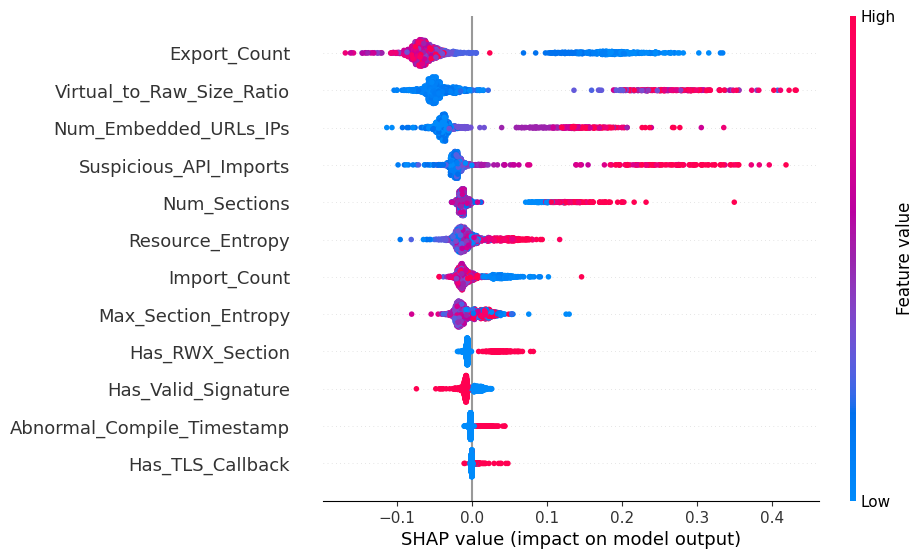

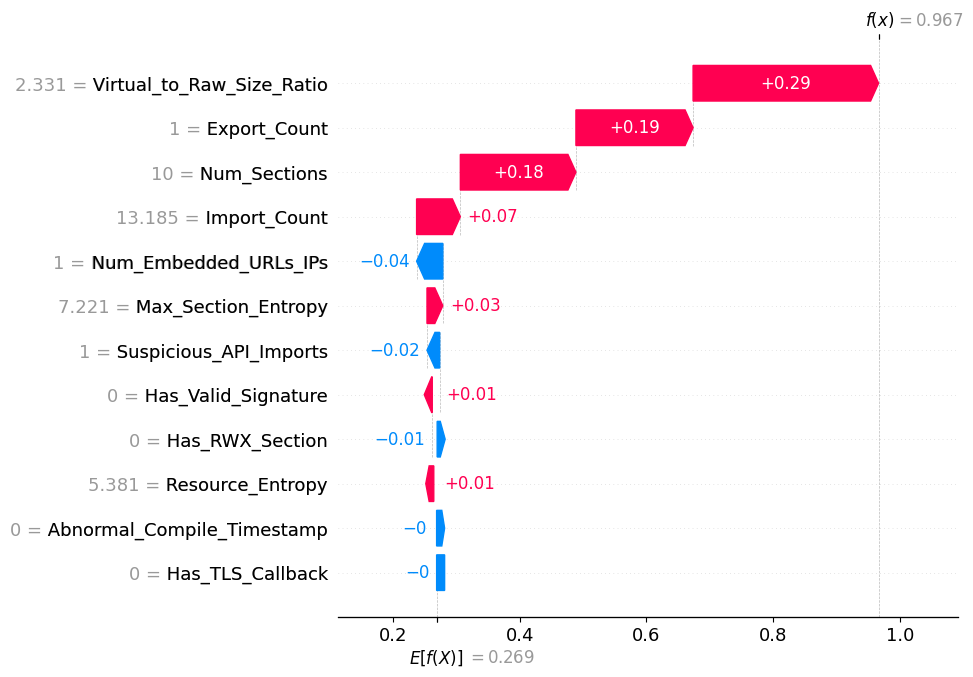

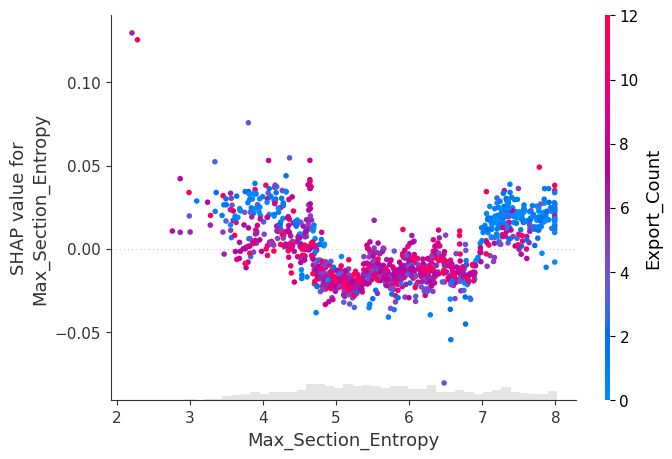

In [16]:
# !pip install shap     # uncomment if needed
import shap

pipe_tree = fitted[TREE_NAME]
imputer = pipe_tree.named_steps["imputer"]
tree_clf = pipe_tree.named_steps["model"]

X_test_imp = pd.DataFrame(imputer.transform(X_test),
                          columns=X_test.columns, index=X_test.index)

explainer = shap.TreeExplainer(tree_clf)
sv = explainer(X_test_imp)
if sv.values.ndim == 3:        # (n, features, classes) -> keep malware class
    sv = sv[:, :, 1]

# Global: beeswarm
shap.plots.beeswarm(sv, max_display=13)

# Local: waterfall for the verified case from the previous cell
shap.plots.waterfall(sv[i], max_display=13)

# Optional: dependence plot
shap.plots.scatter(sv[:, "Max_Section_Entropy"], color=sv)

### Phase 4 — SOC Cost Matrix and Threshold Optimization

**1. Define the cost assumptions**

The SOC uses the following illustrative costs: $25 for a False Positive, $500 for a False Negative and $2,000 for a False Positive in the automatic-blocking scenario.

The total cost is calculated using:

\[
C(\tau)=25FP(\tau)+500FN(\tau)
\]

**2. Threshold optimization**

For analyst-assisted triage, false negatives are considerably more expensive than false positives. Therefore, a relatively low threshold may be preferable to increase malware detection.

For automatic blocking, false positives are much more expensive because legitimate software could be blocked.

Under the simplified assumptions of calibrated probabilities, the theoretical thresholds are 0.0476 for analyst-assisted triage and 0.80 for automatic blocking. However, the final operational thresholds must be selected using development out-of-fold predictions.

**3. Evaluate the frozen threshold**

After selecting the optimal threshold using development data, it must be frozen and evaluated on the test set. The evaluation should report False Positives, False Negatives, precision, recall and total operational cost. The test set must never be used to optimize the threshold.

**4. Compare the two operational scenarios**

In analyst-assisted triage, a lower threshold can be acceptable because suspicious files are reviewed by security analysts. In automatic blocking, a higher threshold is necessary because incorrectly blocking legitimate software could interrupt important business operations. Therefore, the threshold must reflect the operational cost of classification errors.

**5. Cost limitations and dataset prevalence**

The supplied costs are illustrative assumptions rather than measured AtlasPay expenses. The dataset is synthetic and has a malware prevalence of 26.85%, which may not represent the actual prevalence of suspicious PE files in AtlasPay's environment. Real-world deployment requires representative telemetry, probability calibration and continuous monitoring.

**6. SOC capacity check**

AtlasPay processes 12,000 PE files daily and targets a maximum of 120 alerts. This represents an alert rate of:

\[
\frac{120}{12000}\times100=1\%
\]

The model must be evaluated against this operational constraint. However, the synthetic test-set alert count cannot be considered a reliable daily forecast. Real operational data is necessary to estimate actual alert volume.

Theoretical Bayes thresholds (calibrated p): triage = 0.0476, blocking = 0.8000
Selected thresholds (OOF):


threshold
Logistic Regression triage         0.28
                    blocking       0.50
Random Forest       triage         0.33
                    blocking       0.70
LightGBM            triage         0.12
                    blocking       0.63

threshold   TP   TN  FP  FN  precision  recall  \
model               scenario                                                   
Logistic Regression triage         0.28  288  868  10  34     0.9664  0.8944   
                    blocking       0.50  286  870   8  36     0.9728  0.8882   
Random Forest       triage         0.33  288  866  12  34     0.9600  0.8944   
                    blocking       0.70  282  870   8  40     0.9724  0.8758   
LightGBM            triage         0.12  288  852  26  34     0.9172  0.8944   
                    blocking       0.63  283  870   8  39     0.9725  0.8789   

                              alerts_on_test  alert_rate  total_cost  \
model               scenario                                           
Logistic Regression triage               298      0.2483       17250   
                    blocking             294      0.2450       34000   
Random Forest       triage               300      0.2500       17300   
                    blocking             290      0.2417       36000   
LightGBM            triage               314      0.2617       17650   
                    blocking             291      0.2425       35500   

                              cost_at_0.5  
model               scenario               
Logistic Regression triage          18200  
                    blocking        34000  
Random Forest       triage          17725  
                    blocking        35500  
LightGBM            triage          18725  
                    blocking        36500

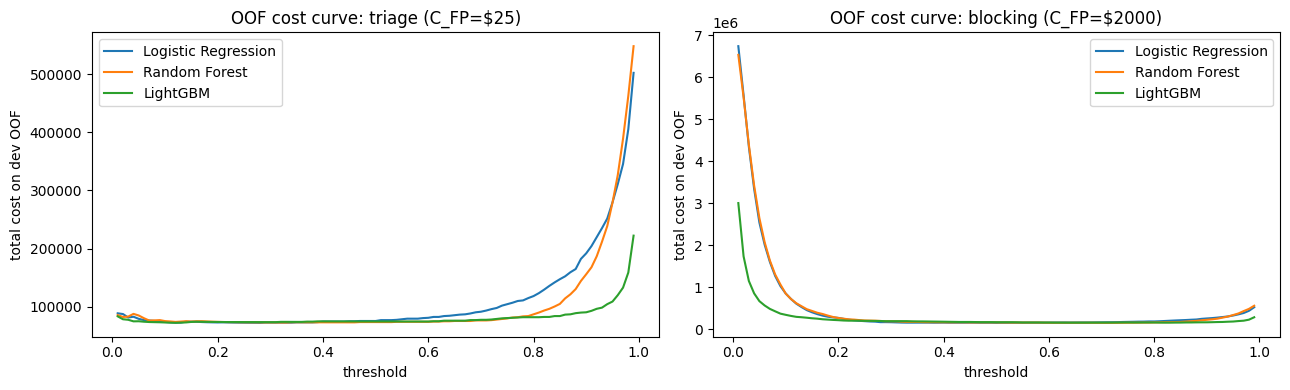


Indicative alerts/day at 12,000 files/day IF test alert rate held in production (it need not):


indicative_alerts_per_day
model               scenario                           
Logistic Regression triage                       2980.0
                    blocking                     2940.0
Random Forest       triage                       3000.0
                    blocking                     2900.0
LightGBM            triage                       3140.0
                    blocking                     2910.0

In [17]:
COST_FP_TRIAGE, COST_FP_BLOCK, COST_FN = 25, 2000, 500
print("Theoretical Bayes thresholds (calibrated p): triage = {:.4f}, blocking = {:.4f}".format(
    COST_FP_TRIAGE / (COST_FP_TRIAGE + COST_FN), COST_FP_BLOCK / (COST_FP_BLOCK + COST_FN)))

# Define SHORTLIST and link models from candidates dictionary
SHORTLIST = ["Logistic Regression", "Random Forest", "LightGBM"]
models = candidates

def counts(y_true, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return tn, fp, fn, tp

def cost(y_true, p, thr, c_fp):
    _, fp, fn, _ = counts(y_true, p, thr)
    return c_fp * fp + COST_FN * fn

grid = np.round(np.linspace(0.01, 0.99, 99), 2)

# 1) OOF probabilities on the DEVELOPMENT set only
oof = {name: cross_val_predict(clone(models[name]), X_dev, y_dev, cv=cv,
                               method="predict_proba", n_jobs=-1)[:, 1]
       for name in SHORTLIST}

# 2) threshold chosen on OOF only
chosen = {}
for name in SHORTLIST:
    for scen, c_fp in [("triage", COST_FP_TRIAGE), ("blocking", COST_FP_BLOCK)]:
        costs = np.array([cost(y_dev.values, oof[name], t, c_fp) for t in grid])
        chosen[(name, scen)] = float(grid[costs.argmin()])   # ties: lowest threshold
print("Selected thresholds (OOF):")
display(pd.Series(chosen, name="threshold").to_frame())

# 3) evaluate ONCE on the lockbox with frozen thresholds
test_p = {name: fitted[name].predict_proba(X_test)[:, 1] for name in SHORTLIST}
rows = []
for name in SHORTLIST:
    for scen, c_fp in [("triage", COST_FP_TRIAGE), ("blocking", COST_FP_BLOCK)]:
        thr = chosen[(name, scen)]
        tn, fp, fn, tp = counts(y_test.values, test_p[name], thr)
        rows.append({"model": name, "scenario": scen, "threshold": thr,
                     "TP": tp, "TN": tn, "FP": fp, "FN": fn,
                     "precision": tp / (tp + fp) if tp + fp else np.nan,
                     "recall": tp / (tp + fn),
                     "alerts_on_test": tp + fp,
                     "alert_rate": (tp + fp) / len(y_test),
                     "total_cost": c_fp * fp + COST_FN * fn,
                     "cost_at_0.5": cost(y_test.values, test_p[name], 0.5, c_fp)})
lock = pd.DataFrame(rows).set_index(["model", "scenario"])
display(lock.round(4))

# Cost curves on OOF (visual check of why thresholds differ)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, (scen, c_fp) in enumerate([("triage", COST_FP_TRIAGE), ("blocking", COST_FP_BLOCK)]):
    for name in SHORTLIST:
        ax[k].plot(grid, [cost(y_dev.values, oof[name], t, c_fp) for t in grid], label=name)
    ax[k].set_title(f"OOF cost curve: {scen} (C_FP=${c_fp})")
    ax[k].set_xlabel("threshold"); ax[k].set_ylabel("total cost on dev OOF"); ax[k].legend()
plt.tight_layout(); plt.show()

# Indicative capacity check ONLY (not a forecast)
print("\nIndicative alerts/day at 12,000 files/day IF test alert rate held in production (it need not):")
display((lock["alert_rate"] * 12000).round(0).rename("indicative_alerts_per_day").to_frame())

### Phase 5 — Final Architecture Decision: CISO Recommendation

AtlasPay needs a static malware detection system capable of identifying suspicious Windows PE files before execution. The positive class is malware (1), while benign files are represented by class (0). The initial deployment should be analyst-assisted rather than autonomous because false positives could interrupt legitimate payment-support operations.

**1. Recommended model**

The final model should be selected by comparing Logistic Regression, Decision Tree, Random Forest and the boosting model using cross-validation PR-AUC, F1-score, recall, computational cost and inference latency. Random Forest and boosting are strong candidates because they can capture nonlinear relationships between PE features. The final choice must be supported by experimental results.

**2. Recommended threshold**

For analyst-assisted triage, the theoretical threshold under the supplied cost assumptions is 0.0476. For automatic blocking, the theoretical threshold is 0.80. The actual operational threshold must be determined using out-of-fold development predictions and then evaluated on the untouched test set.

**3. Supporting evidence**

The model selection should be justified using PR-AUC, F1-score, precision, recall, false-positive and false-negative counts, estimated operational cost, training and inference time, and global and local SHAP explanations.

**4. Operational compatibility**

AtlasPay's target is no more than 120 alerts per day, equivalent to 1% of its daily PE-file submissions. The alert volume must be validated using real operational telemetry. For automatic blocking, the system requires stricter validation because false positives have a much higher operational impact.

**5. Production risks**

The main risks include synthetic-to-real data differences, incorrect or incomplete malware labels, malware prevalence changes, data and concept drift, probability calibration problems, adversarial adaptation, excessive analyst workload and insufficient monitoring.

**6. Final recommendation**

AtlasPay should initially deploy the selected machine-learning model as an analyst-assisted decision-support system. Automatic blocking should not be enabled until the model has been validated using representative real-world PE files, properly calibrated and demonstrated to maintain an acceptable false-positive rate. Continuous monitoring, periodic retraining, analyst feedback and a rollback mechanism should be implemented before production deployment.



# Lab 2 – Static Malware Detection
## Answers and Analysis

---

# Part A – Forensic Data Audit and Problem Formulation

### 1. Dataset overview

The dataset contains **6,000 rows and 15 columns**.

- Benign files: 4,389 (73.2%)
- Malware files: 1,611 (26.8%)
- Malware prevalence: 26.8%
- Duplicate rows: 0
- Duplicate file IDs: 0

Missing values:
- `Import_Count`: 229
- `Resource_Entropy`: 289
- Other columns: 0

There are also 59 sentinel values (`99999.0`) in `Virtual_to_Raw_Size_Ratio`. These values should be treated as invalid or special parser values rather than normal measurements.

### 2. Data quality and feature risks

There are several issues to consider. Missing values can affect model predictions, while sentinel values can distort the feature distribution.

`SHA256_File_ID` should not be used as a predictive feature because it is an identifier, not a meaningful description of the file.

`VT_PostScan_Detections` should also be excluded because it contains information that may only be available after scanning. Using it would create data leakage.

### 3. ML problem statement

The goal is to predict whether a Windows PE file is malicious or benign.

- Target: `Is_Malware`
- Positive class: Malware (1)
- Unit of prediction: One PE file
- Decision time: Before the file is executed
- Intended user: SOC analysts

The model should help analysts identify suspicious files and prioritize their investigation.

### 4. Malware prevalence

The 26.8% malware prevalence comes from a synthetic teaching dataset. It must not be presented as AtlasPay's real malware rate.

If the real production prevalence is lower, the model may generate more false positives compared with true malware alerts. A changing prevalence can also affect precision and the number of alerts analysts receive.

---

# Part B – Feature Forensics and Threat Hypotheses

### 1. Two-feature projection

The plot of `Max_Section_Entropy` and `Suspicious_API_Imports` shows overlap between benign and malicious files.

Some files have higher entropy or suspicious API imports, but these features do not clearly separate every file into one class. This projection only shows two features, so it cannot prove that the complete 12-feature problem is non-linear.

### 2. Possible PE-file archetypes

**Hypothesis 1: Packed or obfuscated files**

Files with high section entropy and a high `Virtual_to_Raw_Size_Ratio` may be compressed, packed, or obfuscated.

However, legitimate installers and compressed applications can have similar characteristics.

**Hypothesis 2: Files with unusual API usage**

Files with suspicious API imports may deserve additional investigation because some APIs can be associated with sensitive system operations.

However, legitimate software can also use these APIs. Their presence alone does not prove malicious activity.

### 3. Static analysis limitations

Static features describe the file, but they do not show exactly what happens when it runs. They cannot prove encryption, packing, malicious execution, or attacker intent.

A useful next step is sandbox analysis. It can help identify unusual network connections, process creation, file changes, and registry activity.

---

# Part C – Leakage-safe Model Comparison

### 1. Cross-validation results

| Model | Train F1 | Validation F1 | PR-AUC | Fit time (s/fold) | Gap |
|---|---:|---:|---:|---:|---:|
| Stacking | 0.9572 | 0.9244 | 0.9084 | 20.8559 | 0.0328 |
| Logistic Regression | 0.9231 | 0.9238 | 0.9080 | 0.0750 | -0.0007 |
| Random Forest | 1.0000 | 0.9237 | 0.9054 | 5.0071 | 0.0763 |
| LightGBM | 0.9979 | 0.9217 | 0.9033 | 0.5472 | 0.0762 |
| Decision Tree | 1.0000 | 0.8301 | 0.7330 | 0.1743 | 0.1699 |

### 2. Overfitting

The Decision Tree has the clearest overfitting problem. Its training F1 is 1.0000, but its validation F1 is only 0.8301. The gap is 0.1699.

This means it performs very well on training data but does not generalize as well to unseen data.

### 3. Comparing competitive models

Logistic Regression and Stacking have very similar validation results.

Stacking has a slightly higher PR-AUC (0.9084), while Logistic Regression has 0.9080. Their validation F1 scores are also close.

However, Logistic Regression is much faster to train and easier to understand. Stacking is more complex and takes longer.

For this reason, Logistic Regression is a reasonable choice even though Stacking has a slightly higher PR-AUC.

### 4. Why PR-AUC is not the only factor

A small difference in PR-AUC does not automatically make one model better for deployment.

We should also consider training time, generalization, interpretability, complexity, and the cost of false positives and false negatives.

### 5. Lockbox test set and preprocessing

The test set is kept separate to provide a final evaluation on unseen data. It should not be used to select models or tune thresholds.

Preprocessing must be fitted inside each training fold. Otherwise, information from validation data could influence the training process and produce overly optimistic results.

---

# Part D – Error Forensics and Local Explanation

### 1. Model disagreement

One disagreement was found for test observation with original row ID **5115**.

- True label: 1 (Malware)
- Logistic Regression probability: 0.426
- Random Forest probability: 0.967
- Classification threshold: 0.50

Logistic Regression classifies this observation as benign, while Random Forest classifies it as malware.

### 2. Feature observations

The observed feature values include:

| Feature | Value |
|---|---:|
| Max_Section_Entropy | 7.221 |
| Import_Count | 13.185 |
| Suspicious_API_Imports | 1 |
| Has_Valid_Signature | 0 |
| Has_RWX_Section | 0 |
| Virtual_to_Raw_Size_Ratio | 2.331 |
| Resource_Entropy | 5.381 |
| Num_Embedded_URLs_IPs | 1 |
| Abnormal_Compile_Timestamp | 0 |
| Num_Sections | 10 |
| Has_TLS_Callback | 0 |
| Export_Count | 1 |

These features provide a possible explanation for the disagreement. The models may interpret the combination of entropy, imports, sections, and other file characteristics differently.

This is an interpretation of the model outputs, not proof that the file is malicious.

### 3. TreeSHAP contributions

The largest positive contributions were:

- `Virtual_to_Raw_Size_Ratio`: +0.29
- `Export_Count`: +0.19
- `Num_Sections`: +0.18

The largest negative contributions were:

- `Num_Embedded_URLs_IPs`: -0.04
- `Suspicious_API_Imports`: -0.02

### 4. Meaning of SHAP values

A positive SHAP value means that the feature pushes the model output towards the positive class. A negative value pushes it away from the positive class.

SHAP explains how the model arrived at its prediction. It does not prove that a feature caused the result or that the file is actually malicious.

### 5. Next investigation

The file should be checked using sandbox or behavioral analysis. This would help verify whether it performs suspicious actions when executed in a controlled environment.

---

# Part E – SOC Cost Model and Threshold Selection

### 1. False positives and false negatives

A false positive is a benign file incorrectly flagged as malware. In analyst-assisted triage, this wastes investigation time.

A false negative is a malicious file that the model misses. This can allow a threat to go unnoticed.

In an inline-blocking scenario, a false positive can be more expensive because it may block legitimate software or interrupt normal business activity.

### 2. Theoretical thresholds

The simplified threshold is:

`T = C_FP / (C_FP + C_FN)`

For analyst-assisted triage:

`T = 25 / (25 + 500) = 0.0476`

For inline blocking:

`T = 2000 / (2000 + 500) = 0.80`

These thresholds assume calibrated probabilities, fixed costs, and no capacity constraints.

### 3. Empirical thresholds

The thresholds selected using development-set OOF probabilities were:

| Model | Triage threshold | Blocking threshold |
|---|---:|---:|
| Logistic Regression | 0.28 | 0.50 |
| Random Forest | 0.33 | 0.70 |
| LightGBM | 0.12 | 0.63 |

These thresholds were selected using development predictions, not the lockbox test results.

### 4. Lockbox evaluation

The following results were obtained using the selected thresholds.

**Logistic Regression**

| Scenario | TP | TN | FP | FN | Precision | Recall | Total cost |
|---|---:|---:|---:|---:|---:|---:|---:|
| Triage | 288 | 868 | 10 | 34 | 0.966 | 0.894 | $17,250 |
| Blocking | 286 | 870 | 8 | 36 | 0.973 | 0.888 | $34,000 |

**Random Forest**

| Scenario | TP | TN | FP | FN | Precision | Recall | Total cost |
|---|---:|---:|---:|---:|---:|---:|---:|
| Triage | 288 | 866 | 12 | 34 | 0.960 | 0.894 | $17,300 |
| Blocking | 282 | 870 | 8 | 40 | 0.972 | 0.876 | $36,000 |

**LightGBM**

| Scenario | TP | TN | FP | FN | Precision | Recall | Total cost |
|---|---:|---:|---:|---:|---:|---:|---:|
| Triage | 288 | 852 | 26 | 34 | 0.917 | 0.894 | $17,650 |
| Blocking | 283 | 870 | 8 | 39 | 0.973 | 0.879 | $35,500 |

For Logistic Regression, the triage cost at threshold 0.50 was $18,200. The blocking cost at threshold 0.50 was $34,000.

The results show that the selected thresholds change the balance between false positives and false negatives. Logistic Regression has a good balance and low operational complexity.

### 5. Theoretical vs empirical thresholds

The theoretical and empirical thresholds can be different because the theoretical calculation assumes perfectly calibrated probabilities and fixed costs.

In practice, model probabilities may not be perfectly calibrated. Finite sample sizes and model limitations can also affect the selected thresholds.

---

# Part F – Operational Feasibility and CISO Recommendation

### 1. Model latency

The Logistic Regression inference time was approximately **2.72 ms per 1,000 files**.

This measures model inference, including the notebook's preprocessing and probability prediction steps. It does not represent the complete production pipeline, which would also need to handle file parsing, feature extraction, I/O, sandbox analysis, and SOC operations.

Therefore, this timing should not be treated as end-to-end processing time.

### 2. Alert volume

At the Logistic Regression triage threshold of 0.28, the test set generated 298 alerts from 1,200 files.

A simple scaling calculation gives:

`(298 / 1200) * 12000 = 2980 alerts per day`

This is only a rough calculation, not a reliable production forecast. The dataset is synthetic, and the real production malware prevalence may be different.

The notebook therefore does not demonstrate that AtlasPay can stay below its target of 120 alerts per day.

### 3. Recommended operational role

I recommend starting with **shadow mode**.

The model can make predictions while analysts continue using their normal process. This allows the SOC to measure performance and alert volume without depending on the model for important decisions.

Autonomous blocking would be too risky at this stage because the dataset is synthetic and production performance has not been validated.

### 4. Conditions before autonomous blocking

Before considering autonomous blocking, AtlasPay should:

1. Test the model using representative real PE files.
2. Check and improve probability calibration.
3. Measure alert volume using real production traffic.
4. Keep analysts involved in reviewing suspicious files.
5. Add drift monitoring to detect changes in the data.
6. Prepare a rollback process in case the model causes problems.
7. Use independent behavioral evidence before blocking important files.

---

# Executive Decision Memo

**To:** AtlasPay CISO  
**Subject:** Initial Recommendation for Static Malware Detection

I recommend starting with Logistic Regression in shadow mode.

The model achieved a validation PR-AUC of 0.9080 and showed a small generalization gap. At the selected triage threshold of 0.28, it achieved a precision of 0.966 and recall of 0.894 on the lockbox test set.

The measured inference time was also low, at approximately 2.72 ms per 1,000 files. However, this does not represent the complete production processing time.

There are still important limitations. The dataset is synthetic and does not represent real AtlasPay traffic. The test results also do not prove that the SOC can stay below the target of 120 alerts per day.

The next step should be testing the model with representative real PE files, checking calibration, measuring actual alert volume, and collecting feedback from SOC analysts.

Autonomous blocking should only be considered after these validation steps are completed.
"""))
